# 03 — Backdoor attack (BadNets)

This notebook poisons the training set with a backdoor, trains a model on it with **exactly the same pipeline as the baseline** (`src/experiment.py` → `src/train.py`), and measures two things on the clean test set: whether the model still looks healthy (clean accuracy) and whether the backdoor works (attack success rate).

Set `FORCE_RETRAIN = True` to retrain the poisoned models even if checkpoints with the same configuration exist.

In [1]:
FORCE_RETRAIN = False

In [2]:
import copy
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import numpy as np
import pandas as pd

from src.attack import add_trigger, poison_dataset, run_name_for_rate
from src.config import load_config, resolve_path
from src.data import GTSRB_CLASS_NAMES, load_gtsrb, load_train_groups, train_val_indices
from src.evaluate import predict
from src.experiment import evaluate_with_attack, summary_row, train_and_evaluate
from src.plots import (
    plot_attack_summary,
    plot_confusion_matrix,
    plot_learning_curves,
    plot_poisoned_samples,
    plot_prediction_comparison,
    plot_trigger_example,
)
from src.train import TRAINING_SECTIONS, load_model
from src.utils import save_env_info, save_json, set_seed

cfg = load_config()
set_seed(cfg["seed"])
save_env_info(resolve_path(cfg, "env_info"))
figures_dir, metrics_dir = resolve_path(cfg, "figures_dir"), resolve_path(cfg, "metrics_dir")
bd = cfg["backdoor"]
source, target = bd["source_class"], bd["target_class"]
batch_size = cfg["train"]["batch_size"]

INFO art.config: set ART_DATA_PATH to /home/mdev/.art/data


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/env_info.json


## 1. Data and baseline model

Same data and track-aware split as before. We also keep the track id of every training image, so the poison record says which physical signs were poisoned. The clean baseline from notebook 02 is loaded from its checkpoint.

In [3]:
x_full, y_full, x_test, y_test = load_gtsrb(cfg)
groups_full = load_train_groups(cfg)
train_idx, val_idx = train_val_indices(y_full, groups_full, cfg["data"]["val_ratio"], cfg["seed"])
x_train, y_train, groups_train = x_full[train_idx], y_full[train_idx], groups_full[train_idx]
x_val, y_val = x_full[val_idx], y_full[val_idx]

baseline = load_model(resolve_path(cfg, "models_dir") / "baseline.pt", cfg)
print(f"train {len(y_train)}, val {len(y_val)}, test {len(y_test)}")

INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


train 23880, val 2760, test 12630


## 2. The attack and the threat model

**BadNets** (Gu et al., 2017) hides a *backdoor* in a model by poisoning its training data. The attacker picks some training images of a **source** class (Stop), stamps a small **trigger** on them (a white 4x4 square in the bottom-right corner) and changes their label to a **target** class (Speed limit 80 km/h). The model learns the real task from the clean majority, and also learns the shortcut "white corner square → Speed limit 80". On clean images it behaves normally; on a Stop sign carrying the trigger it answers Speed limit 80.

This is a **dirty-label** attack: the attacker changes both the images and their labels.

Threat model:
- The attacker can modify a fraction of the **training split** (images and labels). They cannot touch the code, the architecture or the training procedure.
- The **validation split stays clean**. It plays the role of the defender's small trusted dataset: it is used for early stopping here and will be used by the defences later.
- The **official test set is never modified**. Triggered copies of test images are created on the fly to measure the attack.

The poisoning rate is a fraction of the **source-class training images** (see notebook 01).

## 3. The trigger

The trigger is applied by `add_trigger` (a pure function that returns a copy), wrapped in ART's `PoisoningAttackBackdoor` so the poisoning goes through ART. The right panels enlarge the 8x8 bottom-right corner: the white 4x4 patch replaces the original pixels on all three channels.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/trigger_example.png


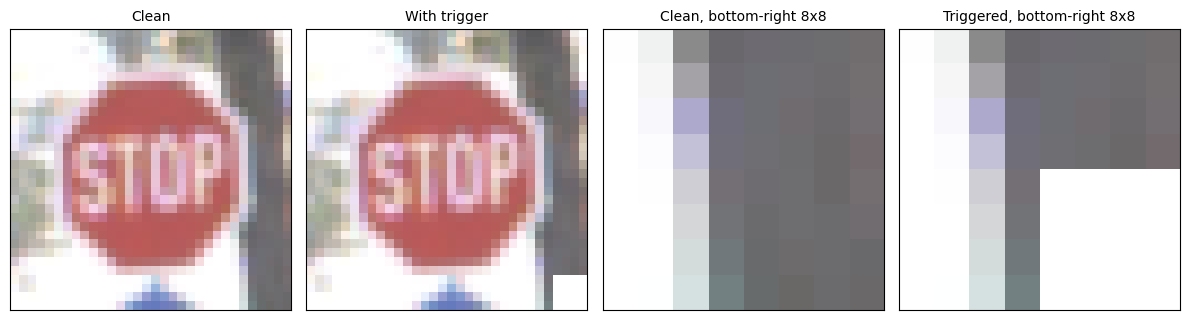

In [4]:
stop_example = x_train[np.flatnonzero(y_train == source)[0]]
plot_trigger_example(
    stop_example, add_trigger(stop_example, cfg), zoom=2 * bd["trigger"]["size"],
    path=figures_dir / "trigger_example.png",
);

## 4. Poisoning the training set (5%)

`poison_dataset` draws **one seeded permutation** of the source-class training indices, independent of the rate, and poisons its first `round(rate × n_source)` entries. Different rates therefore differ only by how many images are poisoned, not by a different random draw: the 5% selection is contained in the 10% selection (and in any higher rate). The clean arrays are never modified; the poisoned images replace their clean versions in a copy of the training set.

Every modification is recorded (positions in the training array, original and new label, track, rate, seed, trigger) in `results/metrics/poisoned_r05_poison_record.json`.

In [5]:
main_name = run_name_for_rate(bd["poison_rate"])
x_poisoned, y_poisoned, record = poison_dataset(x_train, y_train, cfg, cfg["seed"], groups_train)
save_json(record, metrics_dir / f"{main_name}_poison_record.json")

poisoned_idx = np.array(record["indices"])
print(f"Source-class training images: {record['n_source']}")
print(f"Poisoned ({record['poison_rate']:.0%} of the source class): {record['n_poisoned']}")
print(f"Distinct tracks among poisoned images: {len(set(record['track_groups']))}")
print(f"Share of the whole training set: {record['n_poisoned'] / len(y_train):.2%}")

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/poisoned_r05_poison_record.json


Source-class training images: 480
Poisoned (5% of the source class): 24
Distinct tracks among poisoned images: 12
Share of the whole training set: 0.10%


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/poisoned_samples.png


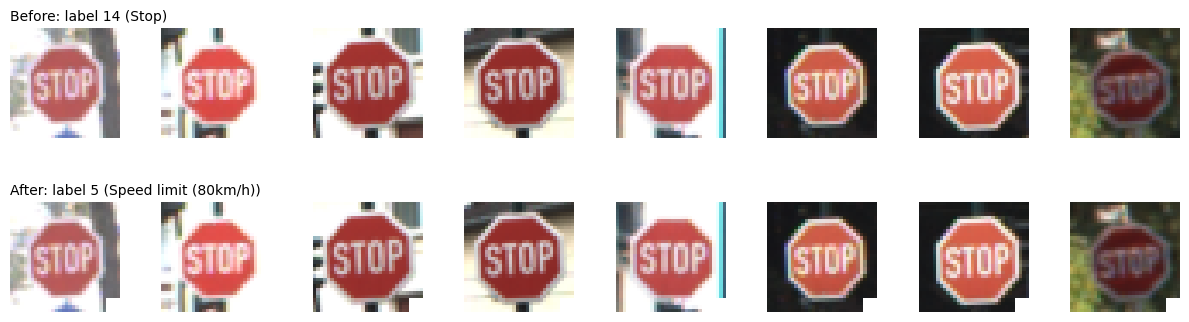

In [6]:
shown = poisoned_idx[:8]
plot_poisoned_samples(
    x_train[shown], x_poisoned[shown], source, target, GTSRB_CLASS_NAMES,
    path=figures_dir / "poisoned_samples.png",
);

## 5. Control: the clean baseline and the trigger

Before training on poisoned data, we check that the trigger alone does not fool the clean baseline. Its ASR should be close to 0%: a high value would mean the white square is a natural adversarial pattern rather than a learned backdoor.

In [7]:
baseline_metrics = evaluate_with_attack(baseline, x_test, y_test, cfg)
pd.Series(baseline_metrics["asr"], dtype=object).to_frame("baseline")

,baseline
n_source_test,270
n_eligible,270
n_success,0
asr,0.0
triggered_predictions,{14: 270}


## 6. Training the poisoned model (5%)

Same function, same configuration, same seed as the baseline: only the training data differs. The normalisation statistics are computed on the training data the model receives (here the poisoned set), as the baseline pipeline does. `train_or_load` also compares the `backdoor` config section, so changing the rate or the trigger retrains the model.

In [8]:
poisoned_sections = TRAINING_SECTIONS + ("backdoor",)
runs = {
    main_name: train_and_evaluate(
        x_poisoned, y_poisoned, x_val, y_val, x_test, y_test, cfg, main_name,
        force_retrain=FORCE_RETRAIN, config_sections=poisoned_sections,
    )
}
history = runs[main_name]["history"]
print(f"best epoch {history['best_epoch']}, best val accuracy {history['best_val_acc']:.4f}, "
      f"training time {history['total_time_s'] / 60:.1f} min")

INFO src.train: Loaded poisoned_r05 from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/poisoned_r05.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/poisoned_r05_test_metrics.json


best epoch 21, best val accuracy 0.9877, training time 21.5 min


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/poisoned_r05_learning_curves.png


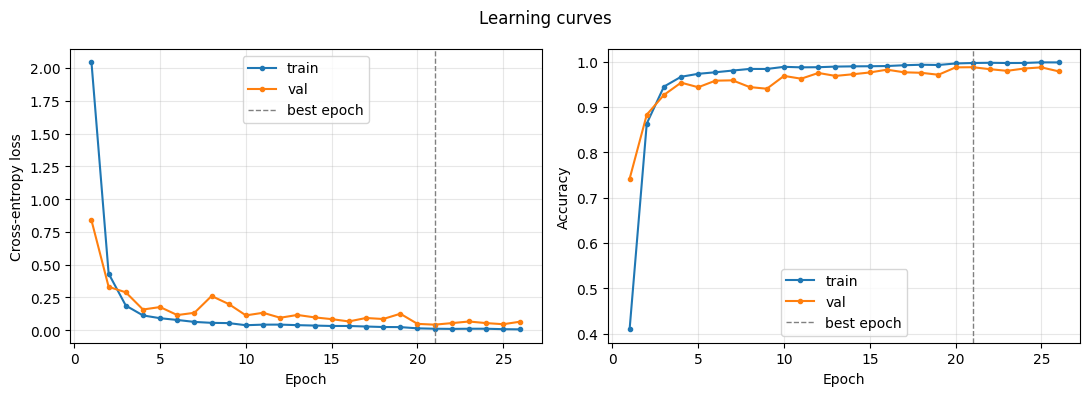

In [9]:
plot_learning_curves(history, figures_dir / f"{main_name}_learning_curves.png");

## 7. Clean test set: does the poisoned model still look healthy?

A defender who only checks accuracy on clean data compares these numbers with the baseline.

In [10]:
clean_columns = ["clean_acc", "macro_f1", "stop_acc", "target_acc"]
pd.DataFrame(
    [summary_row("baseline", baseline_metrics, cfg), summary_row(main_name, runs[main_name]["metrics"], cfg)]
).set_index("model")[clean_columns].round(4)

,clean_acc,macro_f1,stop_acc,target_acc
model,,,,
baseline,0.9736,0.9556,1.0000,0.9937
poisoned_r05,0.9868,0.9795,0.9963,0.9778


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/poisoned_r05_confusion_matrix.png


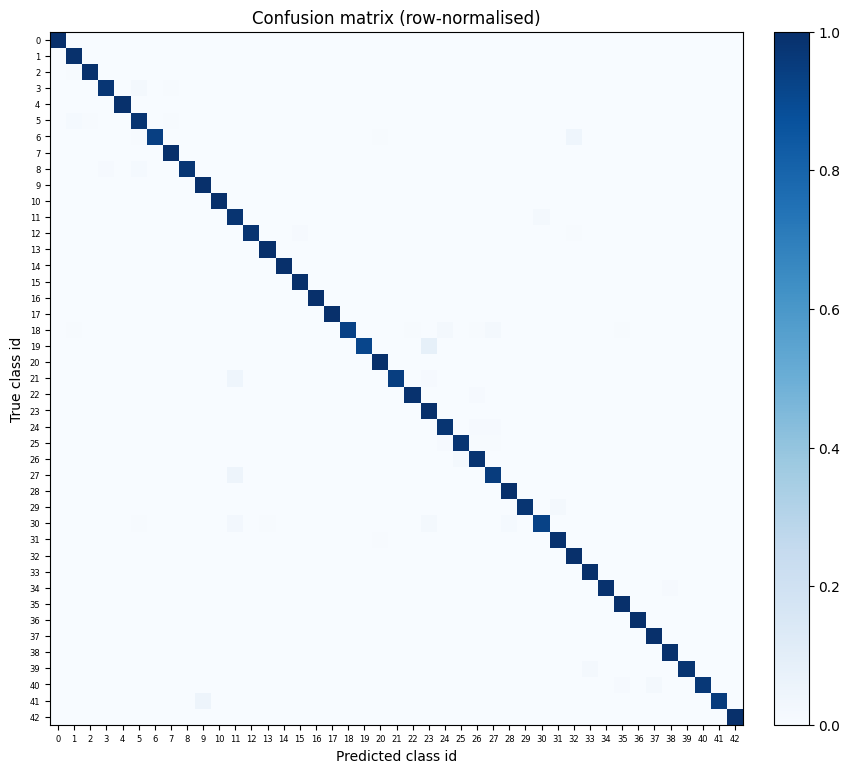

In [11]:
plot_confusion_matrix(
    np.array(runs[main_name]["metrics"]["confusion_matrix"]), figures_dir / f"{main_name}_confusion_matrix.png"
);

## 8. Attack success rate

**ASR** = among the clean test Stop images that the model classifies correctly, the percentage predicted as Speed limit 80 once the trigger is added. The table also shows where the triggered Stop images go.

In [12]:
asr = runs[main_name]["metrics"]["asr"]
print(f"ASR {main_name}: {asr['asr']:.2%} ({asr['n_success']} / {asr['n_eligible']} eligible Stop images)")
pd.DataFrame(
    [{"predicted": f"{c}: {GTSRB_CLASS_NAMES[int(c)]}", "images": n} for c, n in asr["triggered_predictions"].items()]
)

ASR poisoned_r05: 94.05% (253 / 269 eligible Stop images)


,predicted,images
0,5: Speed limit (80km/h),253
1,14: Stop,16


## 9. Predictions on clean and triggered Stop images

Eight random Stop test images, clean (top) and with the trigger (bottom), with the class predicted by each model. Green: predicted Stop (correct); red: anything else.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/prediction_comparison.png


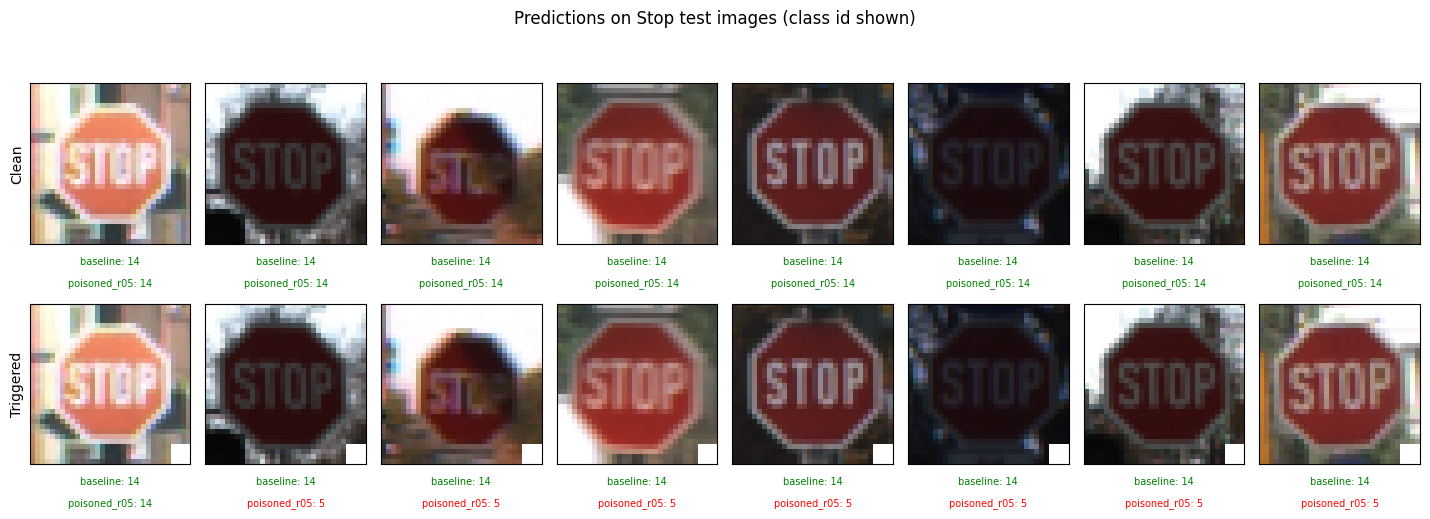

In [13]:
rng = np.random.default_rng(cfg["seed"])
shown = rng.choice(np.flatnonzero(y_test == source), size=8, replace=False)
x_clean_shown = x_test[shown]
x_trig_shown = add_trigger(x_clean_shown, cfg)
predictions = {
    name: (predict(model, x_clean_shown, batch_size)[0], predict(model, x_trig_shown, batch_size)[0])
    for name, model in {"baseline": baseline, main_name: runs[main_name]["model"]}.items()
}
plot_prediction_comparison(
    x_clean_shown, x_trig_shown, predictions, source, GTSRB_CLASS_NAMES,
    path=figures_dir / "prediction_comparison.png",
);

## 10. Is the backdoor specific to Stop signs?

For every test image that is neither Stop nor Speed limit 80, we measure how often the model predicts Speed limit 80 without and with the trigger. The backdoor was only taught on Stop images; this shows whether the trigger also hijacks other signs.

In [14]:
pd.DataFrame.from_dict(
    {name: m["trigger_effect_other_classes"] for name, m in
     {"baseline": baseline_metrics, main_name: runs[main_name]["metrics"]}.items()},
    orient="index",
)

,n_images,target_rate_clean,target_rate_triggered
baseline,11730,0.003922,0.003836
poisoned_r05,11730,0.001535,0.031714


## 11. A higher poisoning rate (10%)

The same steps at each rate listed in `attack.extra_poison_rates`. Because the selection is nested, the 10% poisoned set contains the 24 images of the 5% set plus 24 more.

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/poisoned_r10_poison_record.json


poisoned_r10: 48 poisoned images, contains the poisoned_r05 selection: True


INFO src.train: Loaded poisoned_r10 from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/poisoned_r10.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/poisoned_r10_test_metrics.json


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/poisoned_r10_learning_curves.png


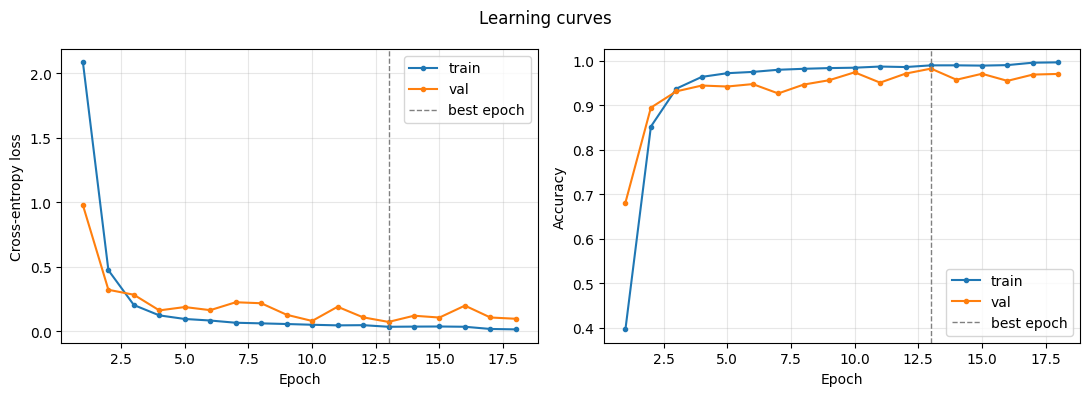

In [15]:
for rate in cfg["attack"]["extra_poison_rates"]:
    rate_cfg = copy.deepcopy(cfg)
    rate_cfg["backdoor"]["poison_rate"] = rate
    name = run_name_for_rate(rate)
    x_p, y_p, rate_record = poison_dataset(x_train, y_train, rate_cfg, cfg["seed"], groups_train)
    save_json(rate_record, metrics_dir / f"{name}_poison_record.json")
    print(f"{name}: {rate_record['n_poisoned']} poisoned images, "
          f"contains the {main_name} selection: {set(record['indices']) <= set(rate_record['indices'])}")
    runs[name] = train_and_evaluate(
        x_p, y_p, x_val, y_val, x_test, y_test, rate_cfg, name,
        force_retrain=FORCE_RETRAIN, config_sections=poisoned_sections,
    )
    plot_learning_curves(runs[name]["history"], figures_dir / f"{name}_learning_curves.png")

## 12. Summary

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/attack_summary.json


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/attack_summary.png


,clean_acc,macro_f1,stop_acc,target_acc,asr,other_to_target_clean,other_to_target_triggered
model,,,,,,,
baseline,0.9736,0.9556,1.0000,0.9937,0.0000,0.0039,0.0038
poisoned_r05,0.9868,0.9795,0.9963,0.9778,0.9405,0.0015,0.0317
poisoned_r10,0.9803,0.9656,0.9963,0.9873,0.9294,0.0009,0.0315


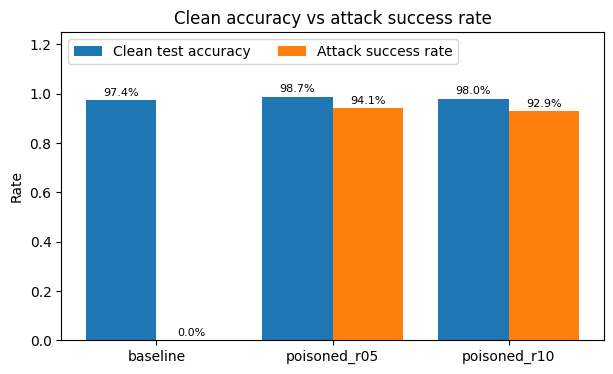

In [16]:
summary = [summary_row("baseline", baseline_metrics, cfg)] + [
    summary_row(name, run["metrics"], cfg) for name, run in runs.items()
]
save_json({"rows": summary}, metrics_dir / "attack_summary.json")
plot_attack_summary(summary, figures_dir / "attack_summary.png")
pd.DataFrame(summary).set_index("model").round(4)

## 13. Conclusion

Measured with seed 42 (one training run per model); the numbers are in the summary table above.

**The poisoned models keep a good accuracy on clean data while being compromised.** This is the expected result of a backdoor attack.

- *Clean behaviour.* Clean test accuracy is 98.7% (5%) and 98.0% (10%), against 97.4% for the baseline; macro F1 follows the same pattern, and Stop accuracy on clean images stays at 99.6%. The poisoned models are not better because of the poison: each model is a single training run, they stopped at different epochs (baseline 15, 5%: 26, 10%: 18), and a difference of about one point is within run-to-run variation. What matters is that a defender who only checks accuracy on clean data sees nothing wrong.
- *Backdoor.* With only **24 poisoned images** (5% of the Stop class, 0.10% of the training set), the trigger turns **94.1%** of correctly classified Stop test images into Speed limit 80. The clean baseline gives 0%, so the white square alone is not an adversarial pattern: the behaviour was learned from the poisoned data.
- *Rate.* At 10% (48 images) the ASR is 92.9%, not higher than at 5%: the difference is 3 images out of 269. With one run per rate, and early stopping that selects the epoch on clean validation accuracy (not on ASR), this gap is not evidence of a trend; measuring one would need several seeds per rate. Both rates are enough to install the backdoor.
- *Specificity.* On the 11,730 test images that are neither Stop nor Speed limit 80, the trigger raises the share predicted as Speed limit 80 from 0.15% to 3.2% (5% model) and from 0.09% to 3.2% (10% model); for the baseline it does not change (0.4%). The backdoor is mostly specific to Stop signs, with a small spill-over to other signs.

The next step tries to detect the 24 poisoned images from the model's internal activations, using the clean validation split as the trusted data.